# Operators and Solvers

This notebook shows the operator workflow of *numgrids*: build differential operators like formulas, then solve boundary value problems, eigenvalue problems and time-dependent problems with a single call each.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numgrids import *

## 1. A boundary value problem

Solve the Poisson equation $\nabla^2 u = -2\pi^2 \sin(\pi x)\sin(\pi y)$ on the unit square with $u = 0$ on the boundary. The exact solution is $u = \sin(\pi x)\sin(\pi y)$.

In [2]:
grid = Grid(x=chebyshev(30, 0, 1), y=chebyshev(30, 0, 1))
L = grid.laplacian_operator()

u = L.solve(lambda x, y: -2 * np.pi**2 * np.sin(np.pi * x) * np.sin(np.pi * y), bcs=0)

exact = grid.evaluate(lambda x, y: np.sin(np.pi * x) * np.sin(np.pi * y))
print(f"max error: {np.max(np.abs(u - exact)):.2e}")

max error: 6.57e-13


Mixed boundary conditions are given per face. Here: $u = 0$ on the left, $u = \sin(\pi y)$ on the right, and insulating (Neumann) walls at the top and bottom.

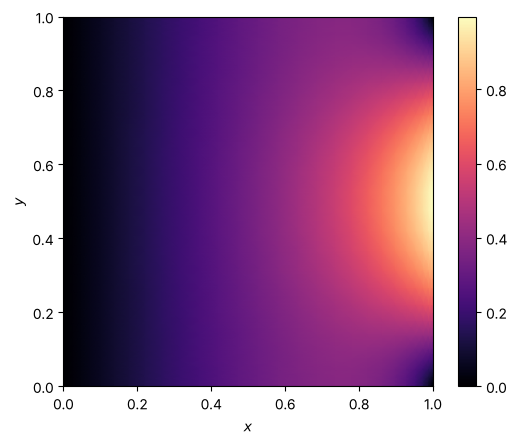

In [3]:
u = L.solve(0.0, bcs={
    "x_low": 0.0,
    "x_high": lambda c: np.sin(np.pi * c[1]),
    "y_low": Neumann(0.0),
    "y_high": Neumann(0.0),
})
grid.plot(u, cmap="magma");

## 2. Operators with variable coefficients: the quantum harmonic oscillator

The Hamiltonian $H = -\frac{1}{2}\frac{d^2}{dx^2} + \frac{1}{2}x^2$ is written down directly. `eig` returns the lowest eigenvalues (exactly $n + \frac{1}{2}$) without spurious modes from the boundary conditions.

In [4]:
grid = Grid(x=chebyshev(80, -10, 10))
x = grid.coords
H = -0.5 * grid.diff_operator(2) + 0.5 * x**2

energies, states = H.eig(k=5, bcs=0)
print(energies)

[0.5 1.5 2.5 3.5 4.5]


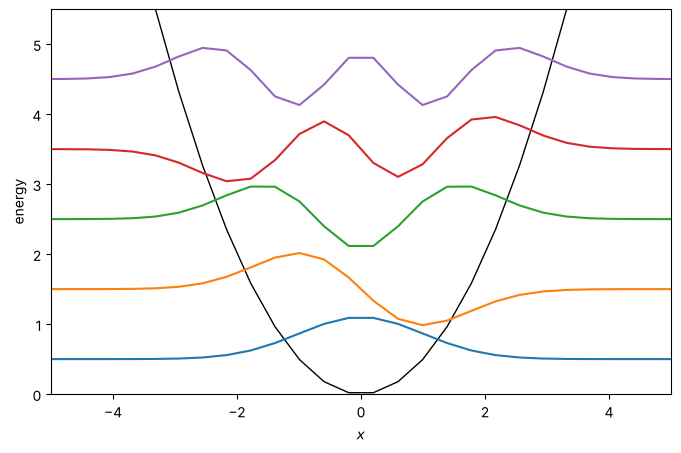

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x, 0.5 * x**2, "k", lw=1)
for E, psi in zip(energies, states):
    psi = psi / np.sqrt(grid.integrate(psi**2))      # normalize to 1
    ax.plot(x, E + 0.8 * psi)
ax.set_xlim(-5, 5); ax.set_ylim(0, 5.5)
ax.set_xlabel("$x$"); ax.set_ylabel("energy");

## 3. Eigenmodes on a curvilinear grid: an annular drum

frequencies: [5.18307212 5.3911812  5.3911812  5.96593369]


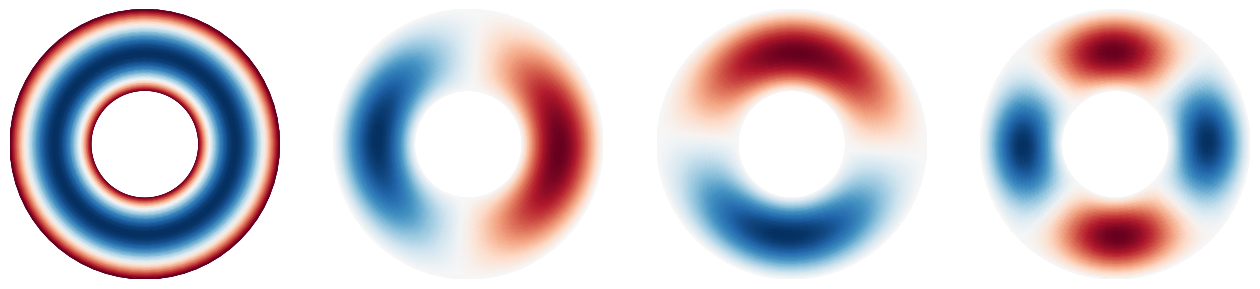

In [6]:
grid = PolarGrid(chebyshev(30, 0.4, 1.0), periodic(64))
vals, modes = (-grid.laplacian_operator()).eig(k=4, bcs=0)
print("frequencies:", np.sqrt(vals))

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, mode in zip(axes, modes):
    grid.plot(mode, ax=ax, colorbar=False, cmap="RdBu")
    ax.set_axis_off()

## 4. Time evolution: the heat equation

`evolve` integrates $\partial_t u = \kappa \nabla^2 u$ with the method of lines. For linear problems the operator can be passed directly; implicit solvers then use its sparse matrix as Jacobian.

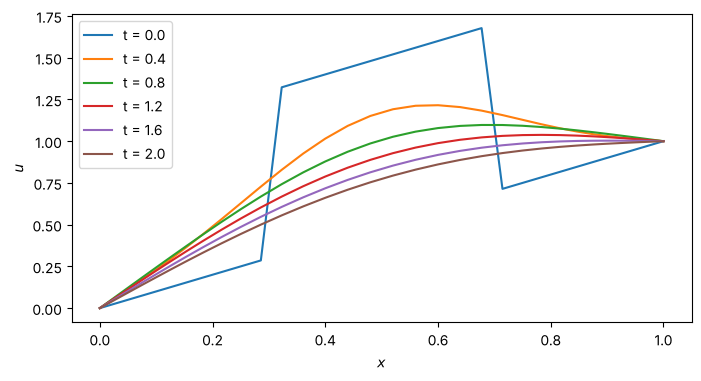

In [7]:
grid = Grid(x=chebyshev(40, 0, 1))
x = grid.coords
u0 = np.where(np.abs(x - 0.5) < 0.2, 1.0, 0.0) + x   # a hot spot plus a gradient

result = evolve(grid, 0.05 * grid.laplacian_operator(), u0, t_span=(0, 2),
                t_eval=np.linspace(0, 2, 6), bcs={"x_low": 0, "x_high": 1}, method="BDF")

fig, ax = plt.subplots(figsize=(8, 4))
for t, u in zip(result.t, result.u):
    ax.plot(x, u, label=f"t = {t:.1f}")
ax.legend(); ax.set_xlabel("$x$"); ax.set_ylabel("$u$");

The solution relaxes to the linear steady state $u = x$ fixed by the boundary values.